# Improving k-Nearest Neighbours on CUB-200-2011

starts from the tuned KNN in [`knn.ipynb`](knn.ipynb) (cosine distance, k = 21, distance weighting, 34.7% test accuracy)
and tests three ways to improve it, on the same data and the same test photos.

| Step | What changes | Section |
|---|---|---|
| Baseline | the tuned KNN from `knn.ipynb`, unchanged | 2 |
| Feature selection: filter | the team's feature sets from `featureSelection.ipynb`, now with the **tuned** KNN | 3 |
| Feature selection: wrapper | remove whole body-part groups, judged by KNN itself | 4 |
| Feature extraction | PCA, LDA, and LDA on certainty-weighted attributes | 5 |
| Comparison, final test, error analysis | | 6-8 |

Ways of encoding "not visible" values were already compared in `annotatorCertainty.ipynb` (variant A was best), so they
are not repeated here.

**Input:** `data/cub_features_A.csv` ([`dataPrep.ipynb`](dataPrep.ipynb)), `data/feature_sets.json`
([`featureSelection.ipynb`](featureSelection.ipynb)), `results/knn_best_params.json` ([`knn.ipynb`](knn.ipynb)), and the
annotators' certainty labels from the raw dataset (section 5 only). **Environment:** `environment-3.12.yml`

## 1. Setup and data

loads the libraries, the prepared table (variant A), the tuned KNN settings from `knn.ipynb` and the
team's feature sets. Every step below is scored with the **same** 10 cross-validation folds of the training photos, so the
steps can be compared fold by fold.

output: the size of the data, the tuned settings and the feature sets available.

In [3]:
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import ttest_rel

from sklearn.base import clone
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_validate
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, cohen_kappa_score,
                             top_k_accuracy_score)

RANDOM_STATE = 42
ROOT = Path.cwd() if (Path.cwd() / 'notebooks').exists() else Path.cwd().parent
DATA = ROOT / 'data'
CUB = next((p.parent for p in (ROOT / 'data' / 'raw').rglob('image_class_labels.txt')), ROOT / 'CUB_200_2011')
RESULTS = ROOT / 'results'
FIGURES = RESULTS / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)
META_COLS = ['image_id', 'class_id', 'class_name', 'is_train', 'is_train_80']
CV = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)
SCORING = {'accuracy': 'accuracy', 'f1_macro': 'f1_macro'}

for path, maker in [(DATA / 'cub_features_A.csv', 'dataPrep.ipynb'), (DATA / 'feature_sets.json', 'featureSelection.ipynb'),
                    (RESULTS / 'knn_best_params.json', 'knn.ipynb')]:
    if not path.exists():
        raise FileNotFoundError(f'{path} not found - run notebooks/{maker} first')

df = pd.read_csv(DATA / 'cub_features_A.csv', index_col='image_id').sort_index()
ATTR = [c for c in df.columns if c not in META_COLS]
X = df[ATTR].astype(np.int8)
y = df.class_id
is_train = df.is_train == 1
y_train, y_test = y[is_train], y[~is_train]
attr_group = pd.Series({c: c.split('::')[0] for c in ATTR})

species_names = df.drop_duplicates('class_id').set_index('class_id').class_name
species_of = species_names.str.split('.', n=1).str[1].str.replace('_', ' ')     # class number -> species name
group_of = species_of.str.split().str[-1]                                         # class number -> bird group

BASE = json.load(open(RESULTS / 'knn_best_params.json'))['params']
knn_base = KNeighborsClassifier(**BASE)
FEATURE_SETS = json.load(open(DATA / 'feature_sets.json'))['sets']

print(f'{len(df):,} photos ({is_train.sum():,} training, {(~is_train).sum():,} test) | {len(ATTR)} attributes')
print('Tuned KNN from knn.ipynb:', BASE)
print('Team feature sets:', {k: len(v) for k, v in FEATURE_SETS.items()})

11,788 photos (5,994 training, 5,794 test) | 312 attributes
Tuned KNN from knn.ipynb: {'metric': 'cosine', 'n_neighbors': 21, 'weights': 'distance'}
Team feature sets: {'all 312': 312, 'per-class top 2': 162, 'per-class top 5': 244, 'per-class top 10': 288, 'ranked top 150': 150, 'ranked top 75': 75, 'ranked top 30': 30}


## 2. Baseline

two small helpers. `record_fixed` scores one fixed model on the 10 folds; `record_search` runs a grid
search and keeps its best setting. Both store the accuracy on each fold, needed for the paired t-test in section 6.
The tuned KNN from `knn.ipynb` is then scored on all 312 attributes: this is the baseline every step is compared with.

output: the baseline's cross-validated accuracy and spread over the 10 folds.

In [12]:
experiments = {}   # name -> fold accuracies, macro F1, settings, unfitted model, input columns or matrix


def record_fixed(name, model, Xin):
    res = cross_validate(model, Xin[is_train], y_train, cv=CV, scoring=SCORING, n_jobs=-1)
    experiments[name] = {'scores': res['test_accuracy'], 'f1': res['test_f1_macro'].mean(),
                         'settings': '', 'model': clone(model), 'X': Xin}
    print(f'{name}: CV accuracy {res["test_accuracy"].mean():.3f} ± {res["test_accuracy"].std():.3f}')


def record_search(name, estimator, grid, Xin):
    gs = GridSearchCV(estimator, grid, cv=CV, scoring=SCORING, refit='accuracy', n_jobs=-1).fit(Xin[is_train], y_train)
    i = gs.best_index_
    scores = np.array([gs.cv_results_[f'split{f}_test_accuracy'][i] for f in range(CV.get_n_splits())])
    experiments[name] = {'scores': scores, 'f1': gs.cv_results_['mean_test_f1_macro'][i],
                         'settings': str(gs.best_params_), 'model': clone(gs.best_estimator_), 'X': Xin}
    print(f'{name}: CV accuracy {scores.mean():.3f} ± {scores.std():.3f}  {gs.best_params_}')


BASELINE = 'Baseline: tuned KNN, all 312 attributes'
record_fixed(BASELINE, knn_base, X)

Baseline: tuned KNN, all 312 attributes: CV accuracy 0.353 ± 0.014


## 3. Feature selection: the team's feature sets

`featureSelection.ipynb` built smaller attribute sets (ranked by Cramér's V without redundant attributes,
and per-species top-k sets) and tested them with a default KNN (k = 10, Euclidean). Here each set is scored with the
tuned KNN instead. The sets were built on the whole training set, so their scores here are slightly optimistic.

output: cross-validated accuracy for each set.

In [13]:
for name in ['per-class top 10', 'per-class top 5', 'per-class top 2', 'ranked top 150', 'ranked top 75', 'ranked top 30']:
    if name in FEATURE_SETS:
        cols = [c for c in FEATURE_SETS[name] if c in X.columns]
        record_fixed(f'Filter: {name} ({len(cols)} attributes)', knn_base, X[cols])

Filter: per-class top 10 (288 attributes): CV accuracy 0.357 ± 0.012
Filter: per-class top 5 (244 attributes): CV accuracy 0.355 ± 0.014
Filter: per-class top 2 (162 attributes): CV accuracy 0.332 ± 0.015
Filter: ranked top 150 (150 attributes): CV accuracy 0.350 ± 0.012
Filter: ranked top 75 (75 attributes): CV accuracy 0.310 ± 0.019
Filter: ranked top 30 (30 attributes): CV accuracy 0.161 ± 0.006


> None of the filtered sets beat the full 312-attribute baseline. Per-class top 10 (288 attributes) and top 5 (244) held steady, but top 30 dropped to 0.161. With only 30 attributes a photo has about 3 ticked attributes on average (down from ~31), so 86.5% of training photos share their exact pattern with a photo of a different species (vs 19 photos, 0.3%, on the full set), and 6.3% become all zeros. KNN is then left choosing between tied neighbours from different species. Selection helped the untuned KNN a little (macro F1), but cosine distance and distance weighting already play down weak attributes, so the tuned model barely changes.

## 4. Feature selection: wrapper method

starting from all 28 body-part groups (bill shape, wing colour, etc.), each round tries removing each
remaining group, keeps the removal that gives the best cross-validated accuracy with the tuned KNN, and stops when no
removal helps. Whole groups are used instead of single attributes to keep the search affordable (28 tests per round
instead of 312). The same folds choose and score the final set, so its score is slightly optimistic.

output: one line per round (group removed, new accuracy), then a table of the steps.

In [14]:
def fold_accuracy(cols):
    res = cross_validate(knn_base, X.loc[is_train, cols], y_train, cv=CV, scoring='accuracy', n_jobs=-1)
    return res['test_score']


groups = list(dict.fromkeys(attr_group))
keep = groups.copy()
best_scores = experiments[BASELINE]['scores']
log = [('all 28 groups', best_scores.mean())]
t0 = time.time()
for round_ in range(10):
    trials = {g: fold_accuracy([c for c in ATTR if attr_group[c] in keep and attr_group[c] != g]) for g in keep}
    g_best = max(trials, key=lambda g: trials[g].mean())
    if trials[g_best].mean() <= best_scores.mean():
        break
    keep.remove(g_best)
    best_scores = trials[g_best]
    log.append((f'removed {g_best}', best_scores.mean()))
    print(f'round {round_ + 1}: removed {g_best:<22} CV accuracy {best_scores.mean():.3f} ({time.time() - t0:.0f}s)')

wrapper_cols = [c for c in ATTR if attr_group[c] in keep]
experiments[f'Wrapper: {len(groups) - len(keep)} body-part groups removed'] = {
    'scores': best_scores, 'f1': np.nan, 'settings': ', '.join(g for g in groups if g not in keep),
    'model': clone(knn_base), 'X': X[wrapper_cols]}
pd.DataFrame(log, columns=['step', 'CV accuracy']).round(4)

round 1: removed has_back_color         CV accuracy 0.359 (14s)


,step,CV accuracy
0,all 28 groups,0.3527
1,removed has_back_color,0.3592


> Only one round helped: dropping has_back_color (upper-body colour, not the photo background) raised CV accuracy from 0.3527 to 0.3592 (p = 0.009). It probably repeats what the wing and upperparts colours already say, and is often hidden when the bird faces the camera. The same folds picked and scored this set, so 0.3592 is a little optimistic.

## 5. Feature extraction

instead of choosing attributes, create new features from all 312, then run KNN on them:
- **PCA:** fewer new features that keep the most overall variation; does not use the species.
- **LDA (Linear Discriminant Analysis):** at most (species − 1) = 199 new features chosen to push species apart; uses the species.
- **LDA on certainty-weighted attributes:** each value becomes +confidence (present), −confidence (absent) or 0 (not visible),
  with confidence 0.5 for guessing, 0.75 for probably and 1 for definitely, from the annotators' certainty labels.

PCA or LDA sits in a `Pipeline` with KNN, so it is refitted on the training part of each fold only. A small grid search
picks the number of new features and the KNN settings.

output: cross-validated accuracy and best settings for each.

In [15]:
KNN_AFTER = {'knn__n_neighbors': [11, 15, 21], 'knn__weights': ['uniform', 'distance'], 'knn__metric': ['euclidean', 'cosine']}
LDA_GRID = {'lda__n_components': sorted({min(n, y_train.nunique() - 1) for n in [32, 64, 128, 199]}), **KNN_AFTER}

t0 = time.time()
record_search('Extraction: PCA', Pipeline([('pca', PCA(random_state=RANDOM_STATE)), ('knn', KNeighborsClassifier())]),
              {'pca__n_components': [50, 100, 200], **KNN_AFTER}, X)
record_search('Extraction: LDA', Pipeline([('lda', LDA()), ('knn', KNeighborsClassifier())]), LDA_GRID, X)

# Certainty-weighted attributes from the raw annotation file (same file as annotatorCertainty.ipynb)
labels_file = CUB / 'attributes' / 'image_attribute_labels_clean.txt'
if labels_file.exists():
    labels = pd.read_csv(labels_file, sep=r'\s+', header=None, usecols=[0, 1, 3], names=['image_id', 'attr_id', 'certainty'])
    names = pd.read_csv(CUB / 'attributes' / 'attributes.txt', sep=' ', header=None,
                        names=['attr_id', 'attr_name']).set_index('attr_id').attr_name
    certainty = labels.pivot(index='image_id', columns='attr_id', values='certainty').rename(columns=names)
    confidence = certainty.loc[X.index, ATTR].replace({1: 0.0, 2: 0.5, 3: 0.75, 4: 1.0})
    X_cw = (2 * X - 1) * confidence          # present -> +confidence, absent -> -confidence, not visible -> 0
    record_search('Extraction: LDA on certainty-weighted', Pipeline([('lda', LDA()), ('knn', KNeighborsClassifier())]),
                  LDA_GRID, X_cw)
else:
    print(f'Skipped certainty-weighted LDA: {labels_file} not found')
print(f'({time.time() - t0:.0f}s)')

Extraction: PCA: CV accuracy 0.359 ± 0.007  {'knn__metric': 'cosine', 'knn__n_neighbors': 21, 'knn__weights': 'distance', 'pca__n_components': 200}
Extraction: LDA: CV accuracy 0.430 ± 0.021  {'knn__metric': 'cosine', 'knn__n_neighbors': 11, 'knn__weights': 'distance', 'lda__n_components': 64}
Extraction: LDA on certainty-weighted: CV accuracy 0.439 ± 0.022  {'knn__metric': 'cosine', 'knn__n_neighbors': 15, 'knn__weights': 'distance', 'lda__n_components': 64}
(115s)


> PCA ignores the species labels, so at 0.359 it barely beats the baseline. LDA uses the labels to pull species apart and reaches 0.430 with 64 components. Certainty-weighted LDA does a bit better (0.439, 64 components): absent attributes become negative confidence scores, so a confident "not there" counts against a species while an unsure guess counts for less.

## 6. Comparing the steps

puts every step side by side. The **paired t-test** compares each step with the baseline fold by fold
(fold 1 with fold 1, and so on); a p-value below 0.05 means the difference is unlikely to be chance. The folds share
training photos, so the p-values are slightly optimistic. The best step is then tested the same way against the runner-up.

output: a table (saved to `results/knn_improvements.csv`), a bar chart with the fold-to-fold spread, and the
best-vs-runner-up test.

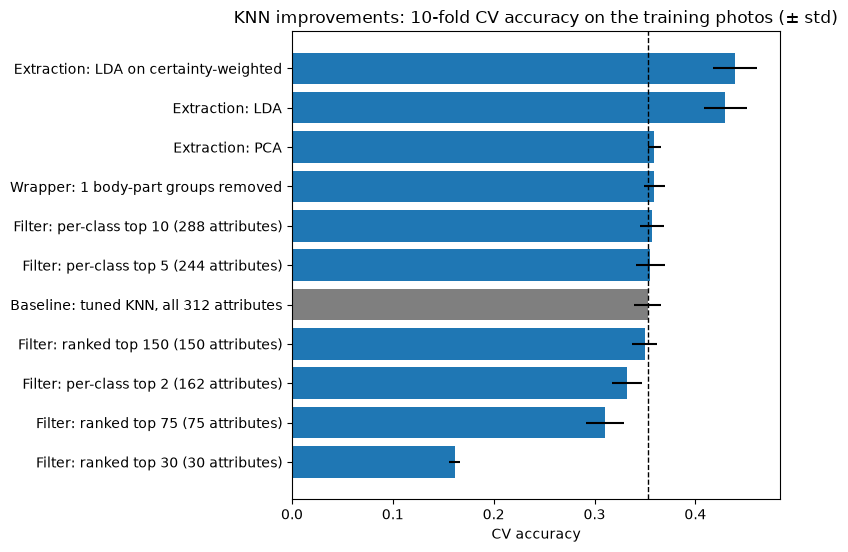

,CV accuracy,± std,CV F-measure (macro),difference vs baseline,paired t-test p
step,,,,,
Extraction: LDA on certainty-weighted,0.4391,0.0218,0.4019,0.0864,0.0000
Extraction: LDA,0.4298,0.0211,0.3945,0.0771,0.0000
Extraction: PCA,0.3594,0.0065,0.3308,0.0067,0.1367
Wrapper: 1 body-part groups removed,0.3592,0.0103,NaN,0.0065,0.0091
Filter: per-class top 10 (288 attributes),0.3567,0.0120,0.3314,0.0040,0.3020
Filter: per-class top 5 (244 attributes),0.3552,0.0143,0.3299,0.0025,0.5262
"Baseline: tuned KNN, all 312 attributes",0.3527,0.0135,0.3276,0.0000,NaN
Filter: ranked top 150 (150 attributes),0.3497,0.0125,0.3243,-0.0030,0.4945
Filter: per-class top 2 (162 attributes),0.3322,0.0150,0.3079,-0.0205,0.0075


In [16]:
base_scores = experiments[BASELINE]['scores']
rows = []
for name, e in experiments.items():
    p = ttest_rel(e['scores'], base_scores).pvalue if name != BASELINE else np.nan
    rows.append({'step': name, 'CV accuracy': e['scores'].mean(), '± std': e['scores'].std(),
                 'CV F-measure (macro)': e['f1'], 'difference vs baseline': e['scores'].mean() - base_scores.mean(),
                 'paired t-test p': p, 'settings': e['settings']})
comparison = pd.DataFrame(rows).set_index('step').sort_values('CV accuracy', ascending=False)
comparison.to_csv(RESULTS / 'knn_improvements.csv')

fig, ax = plt.subplots(figsize=(8, 0.42 * len(comparison) + 1))
c = comparison.sort_values('CV accuracy')
ax.barh(c.index, c['CV accuracy'], xerr=c['± std'], color=['tab:gray' if i == BASELINE else 'tab:blue' for i in c.index])
ax.axvline(base_scores.mean(), color='black', ls='--', lw=1)
ax.set(title='KNN improvements: 10-fold CV accuracy on the training photos (± std)', xlabel='CV accuracy')
plt.tight_layout()
plt.savefig(FIGURES / 'knn_improvements.png', dpi=150, bbox_inches='tight')
plt.show()
comparison.drop(columns='settings').round(4)

In [17]:
first, second = comparison.index[:2]
p = ttest_rel(experiments[first]['scores'], experiments[second]['scores']).pvalue
print(f'{first} vs {second}: difference {comparison.loc[first, "CV accuracy"] - comparison.loc[second, "CV accuracy"]:+.3f}, '
      f'paired t-test p = {p:.3f}')

Extraction: LDA on certainty-weighted vs Extraction: LDA: difference +0.009, paired t-test p = 0.096


> The methods fall into clear groups: both LDA variants improved accuracy significantly, the wrapper gave a small gain, PCA and the mild filters made no real difference, and aggressive filtering hurt. Certainty-weighted LDA had the best CV score (0.439), so it is the final model under the notebook's pick-the-best rule. It is not significantly ahead of plain LDA though (0.430, p = 0.096), so plain LDA is a fair, simpler alternative. Paired t-tests were used because every model was scored on the same folds.

## 7. Final test: baseline vs best step

the baseline and the chosen step are trained on all training photos and tested once on the same
5,794 test photos. `CHOSEN` is the best step on cross-validation; change it to another row name of the table above if two
steps are not significantly different and you prefer the simpler one.

output: one row of test measures per model (saved to `results/knn_improvements_test.csv`). The baseline row should
match `knn.ipynb` (0.347).

In [18]:
CHOSEN = comparison.index[0]          # change to another row name of the table above if you prefer


def fit_test(name):
    e = experiments[name]
    m = clone(e['model']).fit(e['X'][is_train], y_train)
    t0 = time.time()
    pred = m.predict(e['X'][~is_train])
    seconds = time.time() - t0
    return m, pred, m.predict_proba(e['X'][~is_train]), seconds


def evaluate(name, y_true, y_pred, proba, classes, seconds):
    acc = accuracy_score(y_true, y_pred)
    return {'model': name, 'success rate': acc, 'error rate': 1 - acc,
            'precision (macro)': precision_score(y_true, y_pred, average='macro', zero_division=0),
            'recall (macro)': recall_score(y_true, y_pred, average='macro', zero_division=0),
            'F-measure (macro)': f1_score(y_true, y_pred, average='macro', zero_division=0),
            'kappa': cohen_kappa_score(y_true, y_pred),
            'top-5 accuracy': top_k_accuracy_score(y_true, proba, k=5, labels=classes),
            'prediction time (s)': seconds}


m0, pred0, proba0, s0 = fit_test(BASELINE)
m1, pred1, proba1, s1 = fit_test(CHOSEN)
final = pd.DataFrame([evaluate(BASELINE, y_test, pred0, proba0, m0.classes_, s0),
                      evaluate(CHOSEN, y_test, pred1, proba1, m1.classes_, s1)]).set_index('model')
final.to_csv(RESULTS / 'knn_improvements_test.csv')
final.round(3)

,success rate,error rate,precision (macro),recall (macro),F-measure (macro),kappa,top-5 accuracy,prediction time (s)
model,,,,,,,,
"Baseline: tuned KNN, all 312 attributes",0.347,0.653,0.397,0.347,0.342,0.344,0.629,0.810
Extraction: LDA on certainty-weighted,0.442,0.558,0.433,0.443,0.416,0.440,0.702,0.644


> On the test set, certainty-weighted LDA raised top-1 accuracy from 0.347 to 0.442 (+9.5 points), close to its 0.439 CV score, so it did not overfit the folds. Macro F-measure rose from 0.342 to 0.416 and top-5 accuracy from 0.629 to 0.702. Going from 312 attributes to 64 components also cut prediction time from 0.810 s to 0.644 s.

## 8. Error analysis: what did the improvement fix?

compares the baseline's and the improved model's prediction for every test photo.

output: how many photos were fixed and how many broken; the baseline's 10 most confused pairs with their mistakes
before and after; and the change in accuracy for each bird group with 3 or more species.

In [19]:
test = pd.DataFrame({'true': y_test.values, 'before': pred0, 'after': pred1}, index=y_test.index)
test['group'] = test.true.map(group_of)
fixed = ((test.before != test.true) & (test.after == test.true)).sum()
broken = ((test.before == test.true) & (test.after != test.true)).sum()
print(f'Test photos fixed (wrong before, right after): {fixed:,} | broken (right before, wrong after): {broken:,} '
      f'| net gain: {fixed - broken:,}')

pairs = (test[test.before != test.true].groupby(['true', 'before']).size().rename('mistakes before')
         .sort_values(ascending=False).head(10).reset_index())
pairs['mistakes after'] = [((test.true == t) & (test.after == p)).sum() for t, p in zip(pairs.true, pairs.before)]
pairs['true species'] = pairs.true.map(species_of)
pairs['predicted as'] = pairs.before.map(species_of)
pairs[['true species', 'predicted as', 'mistakes before', 'mistakes after']]

Test photos fixed (wrong before, right after): 962 | broken (right before, wrong after): 410 | net gain: 552


,true species,predicted as,mistakes before,mistakes after
0,Common Raven,American Crow,21,21
1,Fish Crow,American Crow,19,19
2,Pelagic Cormorant,American Crow,14,0
3,Blue winged Warbler,Prothonotary Warbler,14,6
4,Pine Warbler,Prothonotary Warbler,13,9
5,Blue Grosbeak,Indigo Bunting,13,16
6,California Gull,Western Gull,11,6
7,Boat tailed Grackle,American Crow,11,7
8,Common Tern,Artic Tern,10,13
9,Louisiana Waterthrush,Northern Waterthrush,10,11


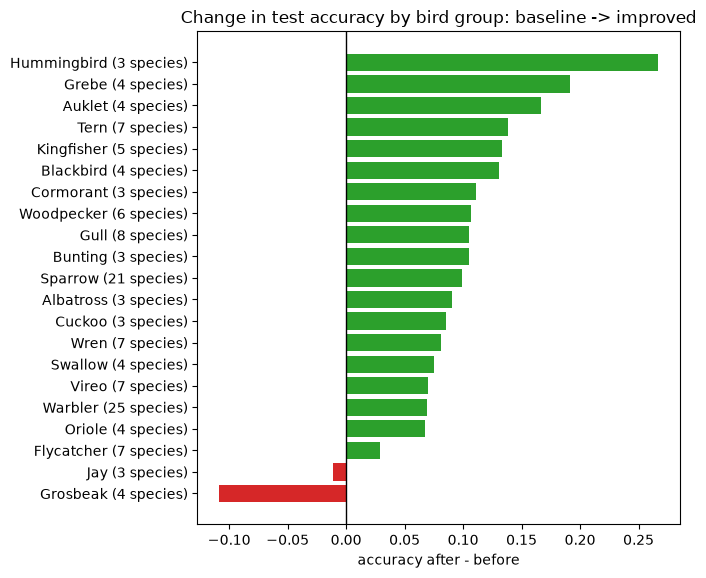

In [20]:
group_counts = group_of.value_counts()
change = test.groupby('group').apply(lambda d: pd.Series({'before': (d.before == d.true).mean(),
                                                          'after': (d.after == d.true).mean()}))
change = change[group_counts.reindex(change.index) >= 3]
change['gain'] = change.after - change.before
change = change.sort_values('gain')

fig, ax = plt.subplots(figsize=(7, max(4, 0.28 * len(change))))
ax.barh([f'{g} ({group_counts[g]} species)' for g in change.index], change.gain,
        color=np.where(change.gain >= 0, 'tab:green', 'tab:red'))
ax.axvline(0, color='black', lw=1)
ax.set(title='Change in test accuracy by bird group: baseline -> improved', xlabel='accuracy after - before')
plt.tight_layout()
plt.savefig(FIGURES / 'knn_improvement_by_group.png', dpi=150, bbox_inches='tight')
plt.show()

> Certainty-weighted LDA fixed 962 test photos and broke 410, a net gain of 552. It helped most where species differ clearly in their attributes: Pelagic Cormorant mistaken for Crow fell from 14 to 0, and hummingbirds gained 0.267. It did not help where the descriptions overlap: Common Raven vs American Crow stayed at 21 mistakes, and grosbeaks dropped 0.108. A linear projection can't separate near-identical attribute vectors, so a CNN such as ResNet-50 working on the images themselves could pick up the visual details the attributes miss.

## 9. Summary

**What happens:** nothing new; write the findings and limitations here.

### Findings

> The primary finding of this notebook is that feature selection barely helped performance, whereas feature extraction (LDA) provided a substantial boost. The tuned KNN baseline (k=21, cosine distance, distance weighting) achieves 0.347 test accuracy, while certainty-weighted LDA compresses the 312 binary attributes into 64 class-separable components to reach 0.442 test accuracy with lower latency (0.644 s). Baseline error analysis on the raw attributes reveals a two-part distribution: 72% of errors cross name-based bird groups, partly due to look-alike attribute descriptions shared across visually distinct birds (such as sparrows predicted as Black-and-white Warblers) and partly due to our crude naming boundary. Performance also exhibits a modest drop when body parts are obscured, falling from 0.34 accuracy (in the under-5% missing attributes bin) to 0.30 across 469 photos in the over-30% missing attributes bin.

### Limitations

> Methodologically, the evaluation relies on a single random seed, and because the cross-validation folds share training data, the resulting p-values are slightly optimistic. Running multiple statistical tests also risks false positives by chance. At the feature level, training accuracy cannot reach 100% because separate species share identical attribute vectors (causing distance ties), while frequent body part obscuration introduces noise. Furthermore, filter and wrapper scores are optimistic because those feature sets were chosen using the same folds that scored them, and certainty labels reflect subjective annotator confidence rather than objective measurements. Linear projections like LDA also cannot separate heavily overlapping attribute vectors, and while KNN prediction time is fast here, its computational cost scales with the size of the training set. Finally, name-based bird groups are crude (using the last word of the species name, causing close relatives like ravens and crows to count as separate groups).